<a href="https://colab.research.google.com/github/Killeryoung/ML/blob/main/%D0%9B%D0%A0_10_Keras_%D0%93%D1%83%D1%80%D0%BA%D0%BE_%D0%94%D0%B0%D0%BD%D0%B8%D0%BB%D0%BE_%D0%A4%D0%86%D0%A2_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  

**Прізвище, ім’я:** Гурко Данило  

**Група:** ФІТ 3-10

**Дата:** 06.11.2026

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [3]:
# Підготуйте імпорти TensorFlow / Keras, NumPy, Matplotlib,
# classification_report, а також потрібних callback-функцій.
# Ваш код:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
print('TensorFlow:', tf.__version__)

TensorFlow: 2.21.0


# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [5]:
# Завантажте Fashion MNIST, визначте class_names.
# Виведіть форми x_train, y_train, x_test, y_test.
# Ваш код:
(x_train_raw, y_train_raw), (x_test_raw, y_test) = keras.datasets.fashion_mnist.load_data()
class_names = ['Футболка/топ', 'Штани', 'Светр', 'Сукня', 'Пальто',
               'Сандалі', 'Сорочка', 'Кросівки', 'Сумка', 'Черевики']
print('x_train:', x_train_raw.shape, 'y_train:', y_train_raw.shape)
print('x_test:', x_test_raw.shape, 'y_test:', y_test.shape)
print('Класів:', len(class_names))

x_train: (60000, 28, 28) y_train: (60000,)
x_test: (10000, 28, 28) y_test: (10000,)
Класів: 10


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

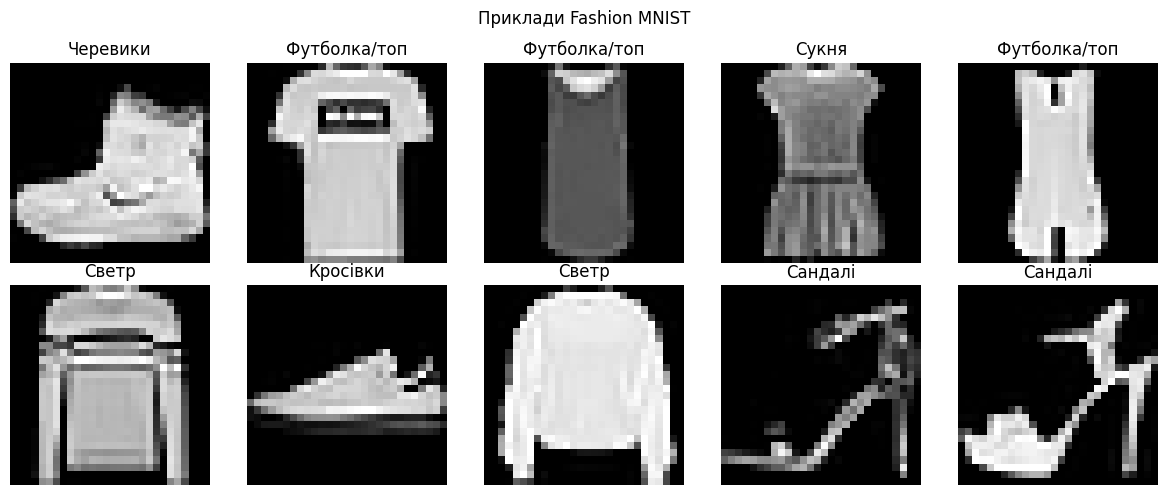

In [6]:
# Побудуйте візуалізацію 10 зображень із підписами класів.
# Ваш код:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train_raw[i], cmap='gray')
    ax.set_title(class_names[y_train_raw[i]])
    ax.axis('off')
plt.suptitle('Приклади Fashion MNIST')
plt.tight_layout()
plt.show()

### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [10]:
# Нормалізуйте навчальні й тестові дані.
# Перевірте діапазони значень.
# Ваш код:
x_train_all = x_train_raw.astype('float32') / 255.0
x_test = x_test_raw.astype('float32') / 255.0

from sklearn.model_selection import train_test_split
x_train, x_val, y_train, y_val = train_test_split(
    x_train_all, y_train_raw, test_size=0.15, random_state=SEED,
    stratify=y_train_raw)
print('Навчальна:', x_train.shape, 'Валідаційна:', x_val.shape, 'Тестова:', x_test.shape)
print('Діапазон:', x_train.min(), x_train.max(), '| Тип:', x_train.dtype)

Навчальна: (51000, 28, 28) Валідаційна: (9000, 28, 28) Тестова: (10000, 28, 28)
Діапазон: 0.0 1.0 | Тип: float32


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [9]:
# Створіть і скомпілюйте модель.
# Ваш код:
model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.25),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.20),
    layers.Dense(10, activation='softmax')
], name='fashion_mnist_baseline')
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
print('256 і 128 нейронів: достатня місткість для базової моделі;')
print('Dropout 0.25/0.20 зменшує перенавчання; Adam(0.001) — стабільний початок.')

256 і 128 нейронів: достатня місткість для базової моделі;
Dropout 0.25/0.20 зменшує перенавчання; Adam(0.001) — стабільний початок.


### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [11]:
# Налаштуйте callbacks і навчіть модель.
# Збережіть history.
# Ваш код:
callbacks_base = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5)
]
history = model.fit(x_train, y_train, validation_data=(x_val, y_val),
                    epochs=30, batch_size=128, callbacks=callbacks_base, verbose=1)

Epoch 1/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7836 - loss: 0.6124 - val_accuracy: 0.8509 - val_loss: 0.4036 - learning_rate: 0.0010
Epoch 2/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8454 - loss: 0.4323 - val_accuracy: 0.8669 - val_loss: 0.3672 - learning_rate: 0.0010
Epoch 3/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8589 - loss: 0.3877 - val_accuracy: 0.8717 - val_loss: 0.3467 - learning_rate: 0.0010
Epoch 4/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8666 - loss: 0.3644 - val_accuracy: 0.8763 - val_loss: 0.3386 - learning_rate: 0.0010
Epoch 5/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8732 - loss: 0.3446 - val_accuracy: 0.8799 - val_loss: 0.3246 - learning_rate: 0.0010
Epoch 6/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8794 - loss: 0.3305 - val_accuracy: 0.8844 - val_loss: 0.3130 - learning_rate: 0.0010
Epoch 7/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8815 - loss: 0.3195 - 

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [12]:
# Виведіть підсумок архітектури моделі.
# Ваш код:
model.summary()
print('Кількість шарів (включно з Flatten та Dropout):', len(model.layers))
print('Кількість параметрів:', model.count_params())

Model: "fashion_mnist_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)

Кількість шарів (включно з Flatten та Dropout): 6
Кількість параметрів: 235146


### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [13]:
# Збережіть навчену модель (.keras).
# За потреби підключіть Google Drive.
# Ваш код:
model.save('fashion_mnist_baseline.keras')
print('Модель збережена: fashion_mnist_baseline.keras')

Модель збережена: fashion_mnist_baseline.keras


### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

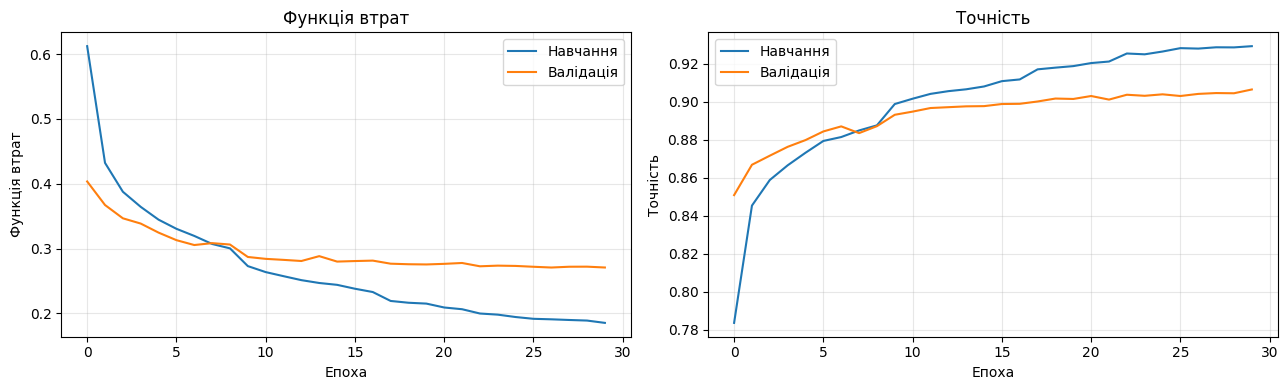

In [14]:
# Побудуйте графіки loss/val_loss та accuracy/val_accuracy.
# Ваш код:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, key, val_key, title in [
    (axes[0], 'loss', 'val_loss', 'Функція втрат'),
    (axes[1], 'accuracy', 'val_accuracy', 'Точність')]:
    ax.plot(history.history[key], label='Навчання')
    ax.plot(history.history[val_key], label='Валідація')
    ax.set(xlabel='Епоха', ylabel=title, title=title)
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [15]:
# Обчисліть loss і accuracy на тестовій вибірці.
# Знайдіть прогнозовані класи та сформуйте classification_report.
# Ваш код:
base_loss, base_acc = model.evaluate(x_test, y_test, verbose=0)
y_pred = np.argmax(model.predict(x_test, verbose=0), axis=1)
print(f'Тестові втрати: {base_loss:.4f}; точність: {base_acc:.4f}')
print('Вимогу accuracy >= 0.87:', 'ВИКОНАНО' if base_acc >= 0.87 else 'НЕ ВИКОНАНО')
print(classification_report(y_test, y_pred, labels=range(10),
                            target_names=class_names, zero_division=0))
cm_base = confusion_matrix(y_test, y_pred, labels=range(10))

Тестові втрати: 0.3076; точність: 0.8961
Вимогу accuracy >= 0.87: ВИКОНАНО
              precision    recall  f1-score   support

Футболка/топ       0.84      0.86      0.85      1000
       Штани       0.99      0.97      0.98      1000
       Светр       0.80      0.83      0.82      1000
       Сукня       0.89      0.91      0.90      1000
      Пальто       0.81      0.84      0.82      1000
     Сандалі       0.98      0.97      0.98      1000
     Сорочка       0.76      0.67      0.71      1000
    Кросівки       0.94      0.97      0.96      1000
       Сумка       0.98      0.98      0.98      1000
    Черевики       0.97      0.96      0.96      1000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

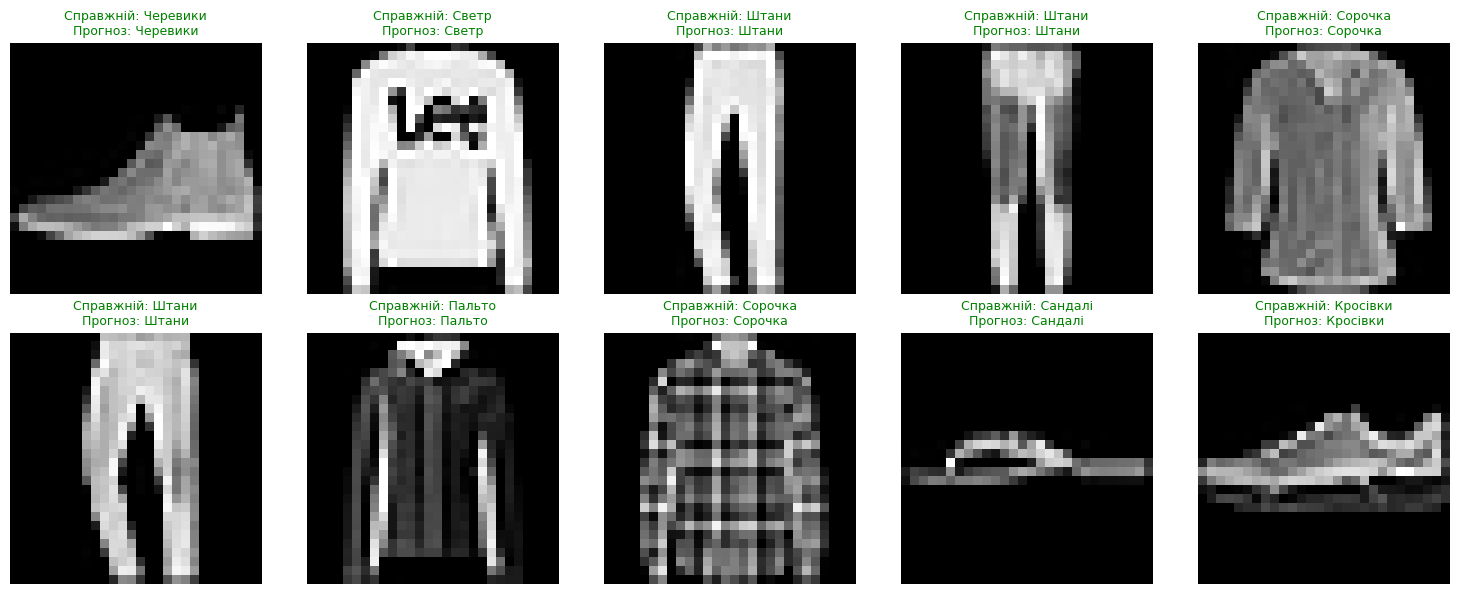

In [16]:
# Візуалізуйте 10 зображень: справжні й прогнозовані класи.
# Ваш код:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_test[i], cmap='gray')
    correct = y_pred[i] == y_test[i]
    ax.set_title(f'Справжній: {class_names[y_test[i]]}\nПрогноз: {class_names[y_pred[i]]}',
                 color='green' if correct else 'red', fontsize=9)
    ax.axis('off')
plt.tight_layout(); plt.show()

**Проміжний висновок до завдання 1**

Запишіть значення тестової accuracy, охарактеризуйте класи з найбільшою кількістю помилок та поясніть, чи виконано вимогу щодо мінімальної точності.

**Ваш висновок:**  
У ході виконання першого завдання було створено та навчено нейронну мережу для класифікації зображень Fashion MNIST. Тестова точність (accuracy) становила 0.8961 (89,61%), а тестові втрати - 0.3076. Найбільше помилок модель допустила під час розпізнавання сорочок (recall 0.67), светрів (0.83) та пальт (0.84), оскільки ці класи мають схожі візуальні ознаки. Найкращі результати отримано для сумок, штанів і сандалій. Вимогу щодо мінімальної точності 0.87 (87%) виконано, оскільки отримана точність становить 89,61%. Отже, нейронна мережа успішно виконує класифікацію зображень одягу.

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [18]:
# За потреби встановіть keras-tuner.
# Імпортуйте RandomSearch та потрібні компоненти Keras.
# Ваш код:
!pip -q install keras-tuner
import keras_tuner as kt
print('Keras Tuner:', kt.__version__)

Keras Tuner: 1.4.8


### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [19]:
# Підготуйте дані для добору гіперпараметрів і фінального тестування.
# Ваш код:
print('Train:', x_train.shape, 'Validation:', x_val.shape, 'Test:', x_test.shape)
assert len(x_train) + len(x_val) == len(x_train_all)

Train: (51000, 28, 28) Validation: (9000, 28, 28) Test: (10000, 28, 28)


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [20]:
# Опишіть функцію build_model(hp).
# Задайте області пошуку гіперпараметрів.
# Ваш код:
def build_model(hp):
    net = keras.Sequential(name='fashion_mnist_tuned')
    net.add(layers.Input(shape=(28, 28)))
    net.add(layers.Flatten())
    n_layers = hp.Int('num_layers', min_value=1, max_value=3, step=1)
    for i in range(n_layers):
        units = hp.Int(f'units_{i}', min_value=32, max_value=512, step=32)
        l2_value = hp.Choice(f'l2_{i}', values=[1e-5, 1e-4, 1e-3])
        net.add(layers.Dense(units, activation='relu',
                             kernel_regularizer=regularizers.l2(l2_value)))
        net.add(layers.Dropout(hp.Choice(f'dropout_{i}', values=[0.1, 0.2, 0.3])))
    net.add(layers.Dense(10, activation='softmax'))
    lr = hp.Choice('learning_rate', values=[0.01, 0.001, 0.0001])
    net.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return net

### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [21]:
# Ініціалізуйте RandomSearch.
# Ваш код:
tuner = kt.RandomSearch(
    build_model, objective='val_accuracy', max_trials=3, executions_per_trial=1,
    directory='keras_tuner_results', project_name='fashion_mnist_lab10',
    overwrite=True, seed=SEED)
print('RandomSearch: 3 спроби, метрика val_accuracy')

RandomSearch: 3 спроби, метрика val_accuracy


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [22]:
# Виконайте пошук, отримайте найкращі гіперпараметри і модель.
# Навчіть вибрану модель без використання тестових даних.
# Ваш код:
callbacks_search = [
    EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5)
]
tuner.search(x_train, y_train, validation_data=(x_val, y_val),
             epochs=15, batch_size=128, callbacks=callbacks_search, verbose=1)
best_hp = tuner.get_best_hyperparameters(1)[0]
print('Найкращі гіперпараметри:', best_hp.values)
# Нова модель з оптимальною конфігурацією: навчаємо лише на train/val.
best_model = tuner.hypermodel.build(best_hp)
best_model.summary()
callbacks_best = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5)
]
best_history = best_model.fit(x_train, y_train, validation_data=(x_val, y_val),
                              epochs=30, batch_size=128,
                              callbacks=callbacks_best, verbose=1)
best_model.save('fashion_mnist_tuned.keras')

Trial 3 Complete [00h 00m 58s]
val_accuracy: 0.8896666765213013

Best val_accuracy So Far: 0.8896666765213013
Total elapsed time: 00h 02m 26s
Найкращі гіперпараметри: {'num_layers': 1, 'units_0': 512, 'l2_0': 1e-05, 'dropout_0': 0.2, 'learning_rate': 0.01, 'units_1': 160, 'l2_1': 0.0001, 'dropout_1': 0.3}


Model: "fashion_mnist_tuned"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 407,050 (1.55 MB)

 Trainable params: 407,050 (1.55 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.7929 - loss: 0.6257 - val_accuracy: 0.8512 - val_loss: 0.4309 - learning_rate: 0.0100
Epoch 2/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8326 - loss: 0.4895 - val_accuracy: 0.8359 - val_loss: 0.4815 - learning_rate: 0.0100
Epoch 3/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8370 - loss: 0.4856 - val_accuracy: 0.8510 - val_loss: 0.4358 - learning_rate: 0.0100
Epoch 4/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8571 - loss: 0.4240 - val_accuracy: 0.8724 - val_loss: 0.3844 - learning_rate: 0.0050
Epoch 5/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.8650 - loss: 0.4013 - val_accuracy: 0.8748 - val_loss: 0.3721 - learning_rate: 0.0050
Epoch 6/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8665 - loss: 0.3941 - val_accuracy: 0.8780 - val_loss: 0.3719 - learning_rate: 0.0050
Epoch 7/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8680 - loss: 0.3901 -

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

Після Keras Tuner: loss=0.3660, accuracy=0.8856


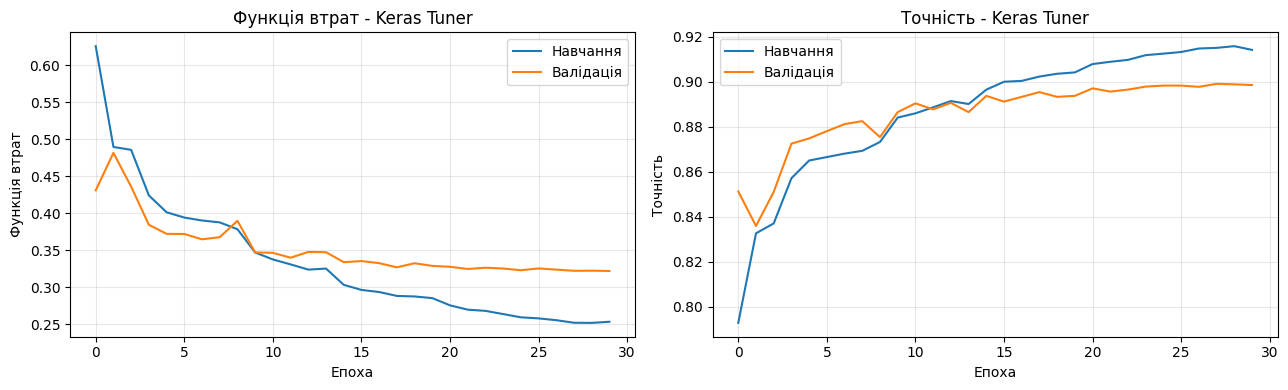

In [25]:
# Оцініть найкращу модель та побудуйте графіки навчання.
# Ваш код:
tuned_loss, tuned_acc = best_model.evaluate(x_test, y_test, verbose=0)
print(f'Після Keras Tuner: loss={tuned_loss:.4f}, accuracy={tuned_acc:.4f}')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric, title in [(axes[0], 'loss', 'Функція втрат'),
                          (axes[1], 'accuracy', 'Точність')]:
    ax.plot(best_history.history[metric], label='Навчання')
    ax.plot(best_history.history['val_' + metric], label='Валідація')
    ax.set(xlabel='Епоха', ylabel=title, title=title + ' - Keras Tuner')
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
tuned_pred = np.argmax(best_model.predict(x_test, verbose=0), axis=1)
cm_tuned = confusion_matrix(y_test, tuned_pred, labels=range(10))

# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів | 2 | 1 |
| Кількість нейронів | 256,128 | 512 |
| Швидкість навчання | 0.001 | 0.01 |
| Точність на тестовій вибірці (accuracy) | 0.8961 | 0.8856 |
| Втрати на тестовій вибірці (loss) | 0.3076 | 0.366 |
| Кількість епох навчання | 30 | 30 |

**У висновках дайте відповідь:**

1. Чи досягнуто точності **не нижче 0,87** у завданні 1?
2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?
3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?
4. Які класи Fashion MNIST класифікувати найскладніше?

**Власні висновки:**  
1. У завданні 1 точність 0.8961; вимогу 0.87 виконано.
2. Після налаштування точність 0.8856, різниця -0.0105. Покращення немає.
3. Найкращі параметри серед 3 спроб: {'num_layers': 1, 'units_0': 512, 'l2_0': 1e-05, 'dropout_0': 0.2, 'learning_rate': 0.01, 'units_1': 160, 'l2_1': 0.0001, 'dropout_1': 0.3}.
4. Результат може змінюватися через випадкову ініціалізацію ваг,
   випадковий пошук конфігурацій і стохастичне навчання.

---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.